<a href="https://colab.research.google.com/github/keyvanmahmoudi/Deep_Learning_Course/blob/main/solutions/Session10_recurrent_networks_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۱۰: شبکه‌های عصبی بازگشتی (RNN) و داده دنباله‌ای

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session10_recurrent_networks.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

</div>

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
np.random.seed(42)

# the synthetic series of the session notebook
t = np.arange(0, 3000)
series = (np.sin(2 * np.pi * t / 50) + 0.5 * np.sin(2 * np.pi * t / 17) + 0.1 * np.random.randn(len(t))).astype(np.float32)
split = 2400
train_series, test_series = series[:split], series[split:]
mean, std = train_series.mean(), train_series.std()
norm = lambda s: (s - mean) / std


class WindowDataset(Dataset):
    def __init__(self, series, window=50):
        self.x, self.window = torch.tensor(series), window

    def __len__(self):
        return len(self.x) - self.window

    def __getitem__(self, i):
        return self.x[i:i + self.window].unsqueeze(-1), self.x[i + self.window].unsqueeze(-1)


def make_loaders(train_part, test_part, window):
    train_ds, test_ds = WindowDataset(train_part, window), WindowDataset(test_part, window)
    return DataLoader(train_ds, batch_size=64, shuffle=True), DataLoader(test_ds, batch_size=256)


class RNNForecaster(nn.Module):
    def __init__(self, hidden_size=64, num_layers=1, cell=nn.RNN):
        super().__init__()
        self.rnn = cell(input_size=1, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1])


@torch.no_grad()
def test_mse(model, loader):
    model.eval()
    se = n = 0
    for X, y in loader:
        se += ((model(X.to(device)) - y.to(device)) ** 2).sum().item(); n += len(y)
    return se / n


def train_regressor(model, train_loader, epochs=15, lr=1e-3, clip=1.0, log_batches=False):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    batch_losses = []
    for _ in range(epochs):
        model.train()
        for X, y in train_loader:
            loss = nn.functional.mse_loss(model(X.to(device)), y.to(device))
            opt.zero_grad(); loss.backward()
            if clip is not None:
                nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            batch_losses.append(loss.item())
    return (model, batch_losses) if log_batches else model

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

`MyRNN` را طوری تغییر دهید که `num_layers` را پشتیبانی کند و خروجی را با `nn.RNN(num_layers=2)` مقایسه کنید.

</div>

In [2]:
class MyRNN(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers=1):
        super().__init__()
        self.hidden_size, self.num_layers = hidden_size, num_layers
        self.W_xh = nn.ModuleList([nn.Linear(input_size if l == 0 else hidden_size, hidden_size) for l in range(num_layers)])
        self.W_hh = nn.ModuleList([nn.Linear(hidden_size, hidden_size, bias=False) for _ in range(num_layers)])

    def forward(self, x):
        """x: (batch, seq, input) -> output of the last layer (batch, seq, hidden), h_n (num_layers, batch, hidden)"""
        layer_input, h_n = x, []
        for l in range(self.num_layers):                      # layer l reads the whole output sequence of layer l-1
            h = torch.zeros(x.shape[0], self.hidden_size, device=x.device)
            outputs = []
            for t in range(x.shape[1]):
                h = torch.tanh(self.W_xh[l](layer_input[:, t]) + self.W_hh[l](h))
                outputs.append(h)
            layer_input = torch.stack(outputs, dim=1)
            h_n.append(h)
        return layer_input, torch.stack(h_n)


ref = nn.RNN(input_size=3, hidden_size=5, num_layers=2, batch_first=True)
mine = MyRNN(3, 5, num_layers=2)
with torch.no_grad():
    for l in range(2):
        mine.W_xh[l].weight.copy_(getattr(ref, f'weight_ih_l{l}'))
        mine.W_xh[l].bias.copy_(getattr(ref, f'bias_ih_l{l}') + getattr(ref, f'bias_hh_l{l}'))
        mine.W_hh[l].weight.copy_(getattr(ref, f'weight_hh_l{l}'))

x = torch.randn(4, 7, 3)
(out_ref, h_ref), (out_mine, h_mine) = ref(x), mine(x)
print('output shapes:', tuple(out_ref.shape), tuple(out_mine.shape), '| h_n shapes:', tuple(h_ref.shape), tuple(h_mine.shape))
print('outputs match:', torch.allclose(out_ref, out_mine, atol=1e-6), '| h_n match:', torch.allclose(h_ref, h_mine, atol=1e-6))

output shapes: (4, 7, 5) (4, 7, 5) | h_n shapes: (2, 4, 5) (2, 4, 5)
outputs match: True | h_n match: True


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

در RNN چندلایه، لایهٔ $l$ کل دنبالهٔ خروجی لایهٔ $l-1$ را به‌عنوان ورودی می‌خواند. `output` فقط خروجی **لایهٔ آخر** در همهٔ گام‌هاست، اما `h_n` حالت پنهان **آخرین گام** را برای **هر لایه** دارد. وزن‌های لایهٔ دوم در PyTorch با پسوند `_l1` ذخیره می‌شوند و ابعاد ورودی آن‌ها `hidden_size` است، نه `input_size`.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

در مسئله سری زمانی، طول پنجره را ۱۰، ۲۵ و ۱۰۰ بگیرید. کدام بهتر است؟ چرا پنجره ۱۰ کافی نیست؟ (راهنمایی: دوره موج‌ها.)

</div>

In [3]:
results = {}
for window in (10, 25, 100):
    torch.manual_seed(0)
    tr_loader, te_loader = make_loaders(norm(train_series), norm(test_series), window)
    model = train_regressor(RNNForecaster(), tr_loader)
    results[window] = test_mse(model, te_loader)
    print(f'window = {window:3d}: test MSE {results[window]:.4f}')
print(f'noise floor: {0.1 ** 2 / std ** 2:.4f}')

window =  10: test MSE 0.0447


window =  25: test MSE 0.0239


window = 100: test MSE 0.0209
noise floor: 0.0156


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

سری از دو موج با دورهٔ ۵۰ و ۱۷ ساخته شده است. پنجرهٔ ۱۰ گامی حتی یک دورهٔ کامل از موج سریع‌تر (۱۷) را هم نمی‌بیند و از موج کند (۵۰) فقط یک‌پنجم دوره را می‌بیند. از روی چند نقطهٔ نویزی، تشخیص اینکه هر موج در چه **فاز**ی است دشوار است، پس خطا بیشتر می‌ماند. پنجره‌های ۲۵ و ۱۰۰ دست‌کم یک دورهٔ کامل از موج سریع را پوشش می‌دهند و خطا به سطح نویز نزدیک می‌شود. پنجرهٔ ۱۰۰ لزوماً از ۲۵ خیلی بهتر نیست، چون RNN ساده وابستگی‌های بلند را به‌سختی یاد می‌گیرد و آموزشش هم کندتر است. **قاعده:** پنجره باید دست‌کم یک دوره از مهم‌ترین الگوی تکراری داده را در بر بگیرد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

در `train_regressor`، Gradient Clipping را حذف و نرخ یادگیری را ۰٫۰۵ کنید. نمودار Loss در هر Batch را رسم کنید.

</div>

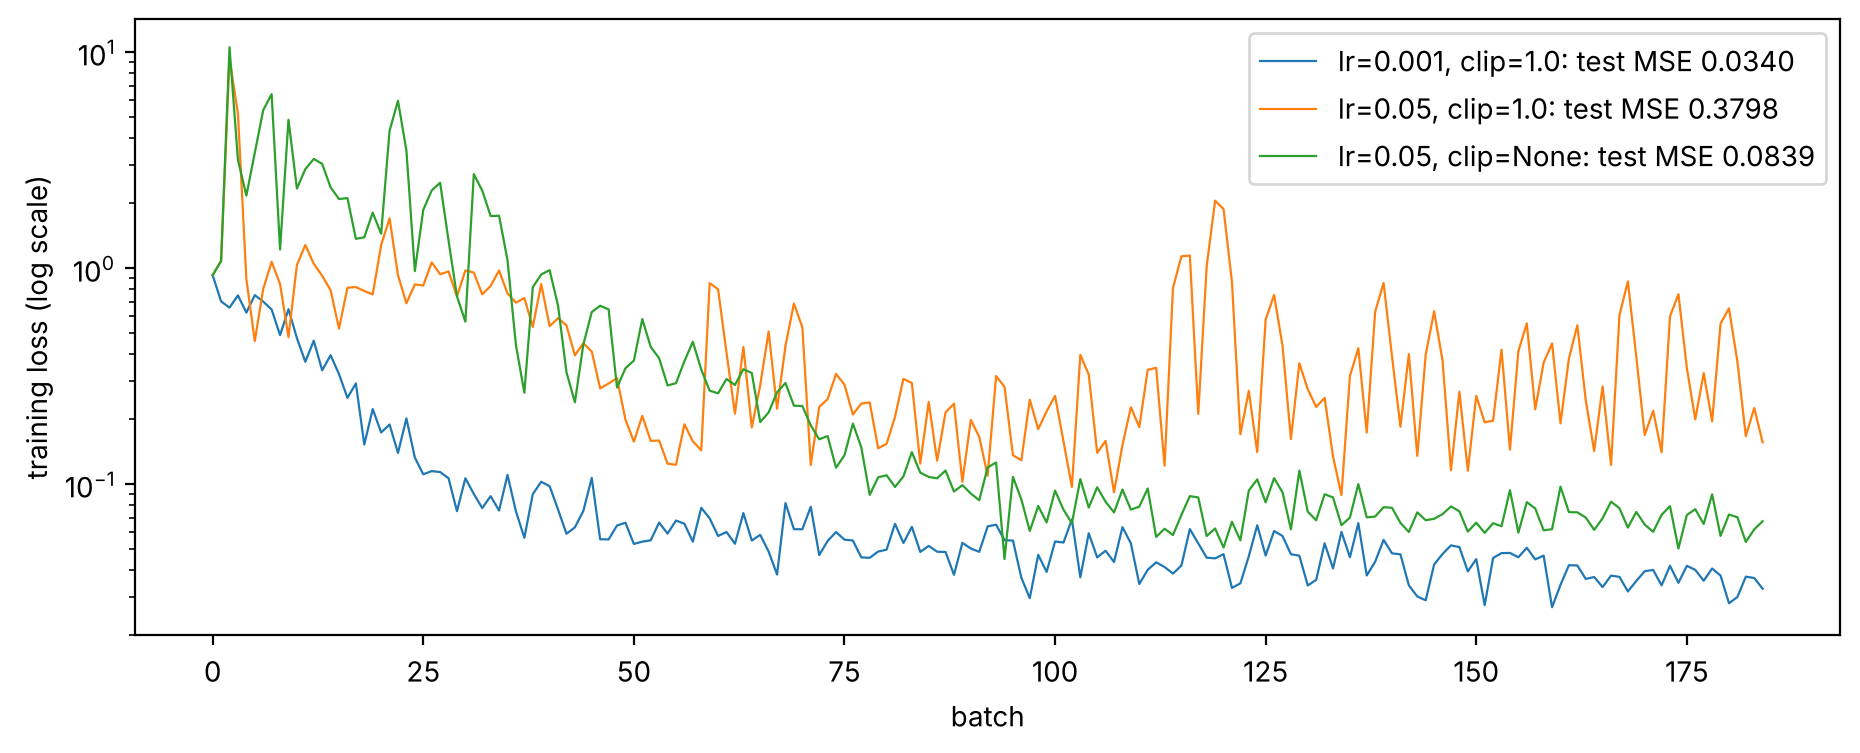

In [4]:
tr_loader, te_loader = make_loaders(norm(train_series), norm(test_series), 50)
fig, ax = plt.subplots(figsize=(11, 4))
for clip, lr in [(1.0, 1e-3), (1.0, 0.05), (None, 0.05)]:
    torch.manual_seed(0)
    model, losses = train_regressor(RNNForecaster(), tr_loader, epochs=5, lr=lr, clip=clip, log_batches=True)
    label = f'lr={lr}, clip={clip}'
    ax.semilogy(losses, lw=0.8, label=f'{label}: test MSE {test_mse(model, te_loader):.4f}')
ax.set_xlabel('batch'); ax.set_ylabel('training loss (log scale)'); ax.legend(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با نرخ یادگیری ۰٫۰۵، نمودار Loss در هر Batch پر از **جهش‌های ناگهانی** است و خطای آزمون چند برابر حالت $10^{-3}$ می‌ماند، **چه با Clipping و چه بدون آن**. در این اجرا Clipping حتی کمکی نکرد. دلیل: به‌روزرسانی Adam تقریباً $\eta\,\hat{m}/\sqrt{\hat{v}}$ است و نسبت به **مقیاس** گرادیان تقریباً بی‌تفاوت است. اگر همهٔ گرادیان‌ها را کوچک کنیم، $\hat{m}$ و $\sqrt{\hat{v}}$ هر دو کوچک می‌شوند و طول قدم تقریباً همان $\eta$ می‌ماند. پس با Adam، طول قدم را عملاً نرخ یادگیری تعیین می‌کند. Clipping برای SGD (که قدمش مستقیماً متناسب با گرادیان است) و برای مهار **یک** Batch استثنایی با گرادیان عظیم بسیار مؤثر است، اما نرخ یادگیری نامناسب را جبران نمی‌کند. **درس:** اول نرخ یادگیری را درست انتخاب کنید؛ Clipping یک کمربند ایمنی است، نه فرمان.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

`RNNForecaster` را با `cell=nn.GRU` و `cell=nn.LSTM` آموزش دهید و خطای آزمون را مقایسه کنید.

</div>

In [5]:
for name, cell in [('RNN', nn.RNN), ('GRU', nn.GRU), ('LSTM', nn.LSTM)]:
    torch.manual_seed(0)
    start = time.time()
    model = train_regressor(RNNForecaster(cell=cell), tr_loader)
    n_par = sum(p.numel() for p in model.parameters())
    print(f'{name:4}: parameters {n_par:6,} | test MSE {test_mse(model, te_loader):.4f} | {time.time() - start:.0f}s')

RNN : parameters  4,353 | test MSE 0.0205 | 128s


GRU : parameters 12,929 | test MSE 0.0332 | 202s


LSTM: parameters 17,217 | test MSE 0.0246 | 20s


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

`RNNForecaster` بدون هیچ تغییری با `nn.GRU` و `nn.LSTM` کار می‌کند، چون خروجی اول همهٔ این ماژول‌ها همان دنبالهٔ حالت‌های پنهان است. (خروجی دوم LSTM یک زوج `(h_n, c_n)` است که ما از آن استفاده نمی‌کنیم.) GRU سه برابر و LSTM چهار برابر RNN ساده پارامتر دارند. در این مسئله با پنجرهٔ ۵۰ و الگوی کوتاه‌مدت، RNN ساده حتی کمی بهتر است: وابستگی بلندمدتی وجود ندارد که دروازه‌ها به کارش بیایند، و مدل‌های بزرگ‌تر در ۱۵ Epoch کمتر همگرا شده‌اند. (زمان‌های چاپ‌شده در این اجرا به‌خاطر اجرای همزمان چند برنامه روی CPU قابل مقایسه نیستند.) برتری واقعی LSTM و GRU در وابستگی‌های **بلندمدت** است؛ آزمایش حافظه در جلسه را ببینید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۵

یک سری زمانی واقعی (مثلاً داده روزانه مصرف برق یا دمای یک شهر از Kaggle) را با همین کد پیش‌بینی کنید و با خط مبنای ساده مقایسه کنید.

</div>

        Date  Temp
0 1981-01-01  20.7
1 1981-01-02  17.9
2 1981-01-03  18.8 
 3650 days from 1981-01-01 to 1990-12-31


GRU   : RMSE 2.20 °C
naive : RMSE 2.49 °C  (tomorrow = today)


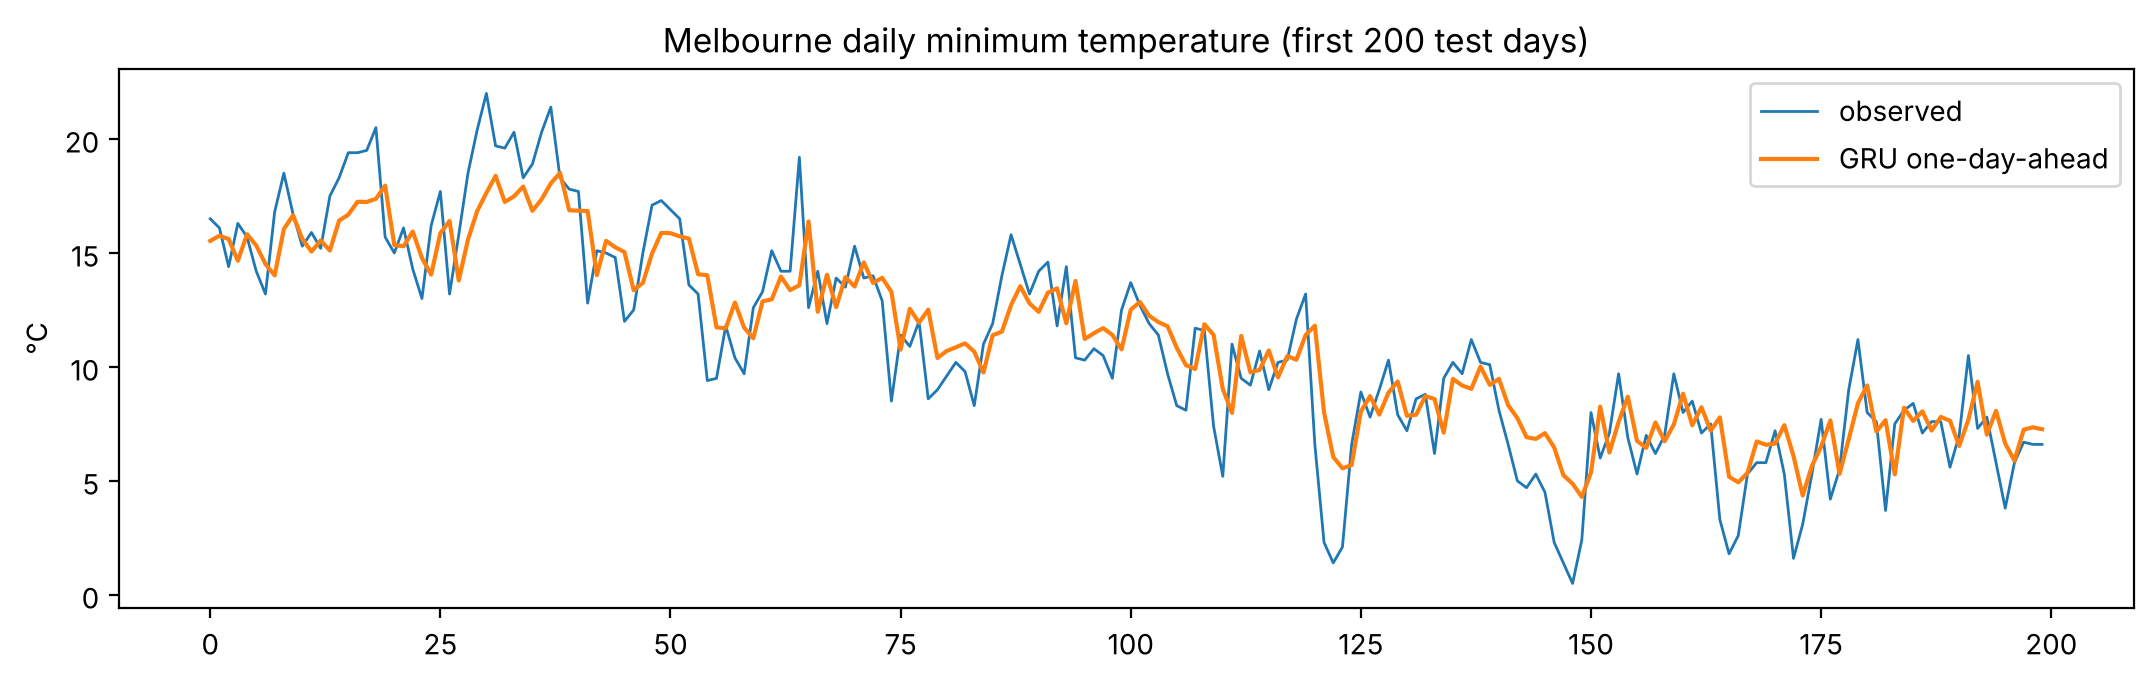

In [6]:
URL = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv'
temps = pd.read_csv(URL, parse_dates=['Date'])
print(temps.head(3), '\n', len(temps), 'days from', temps['Date'].min().date(), 'to', temps['Date'].max().date())
values = temps['Temp'].to_numpy(dtype=np.float32)

cut = int(len(values) * 0.8)                                   # chronological split
tr, te = values[:cut], values[cut:]
mu, sigma = tr.mean(), tr.std()
WIN = 30
tr_loader_t, te_loader_t = make_loaders((tr - mu) / sigma, (te - mu) / sigma, WIN)

torch.manual_seed(0)
temp_model = train_regressor(RNNForecaster(cell=nn.GRU), tr_loader_t, epochs=20)
model_mse = test_mse(temp_model, te_loader_t) * sigma ** 2      # back to squared degrees
te_n = (te - mu) / sigma
naive_mse = np.mean((te_n[WIN:] - te_n[WIN - 1:-1]) ** 2) * sigma ** 2
print(f'GRU   : RMSE {np.sqrt(model_mse):.2f} °C')
print(f'naive : RMSE {np.sqrt(naive_mse):.2f} °C  (tomorrow = today)')

with torch.no_grad():
    temp_model.eval()
    X_all = torch.stack([te_loader_t.dataset[i][0] for i in range(len(te_loader_t.dataset))]).to(device)
    preds = temp_model(X_all).cpu().numpy().ravel() * sigma + mu
plt.figure(figsize=(13, 3.5))
plt.plot(te[WIN:WIN + 200], lw=1, label='observed'); plt.plot(preds[:200], lw=1.5, label='GRU one-day-ahead')
plt.ylabel('°C'); plt.title('Melbourne daily minimum temperature (first 200 test days)'); plt.legend(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

داده، کمینهٔ دمای روزانهٔ ملبورن در سال‌های ۱۹۸۱ تا ۱۹۹۰ است. برخلاف سری مصنوعی، دادهٔ واقعی نویز بسیار زیادی دارد: دمای فردا تا حد زیادی به رویدادهای جوی غیرقابل پیش‌بینی بستگی دارد. نتیجه معمولاً این است که GRU فقط **اندکی** از خط مبنای «فردا = امروز» بهتر است. بخش بزرگی از سود آن از الگوی فصلی و میانگین چند روز اخیر می‌آید. در سری‌های زمانی واقعی، شکست دادن خط مبنای ساده اصلاً بدیهی نیست؛ پیش از ادعای موفقیت مدل، همیشه با آن مقایسه کنید.

</div>